Airflow: to create, schedule and monitor tasks and workflows

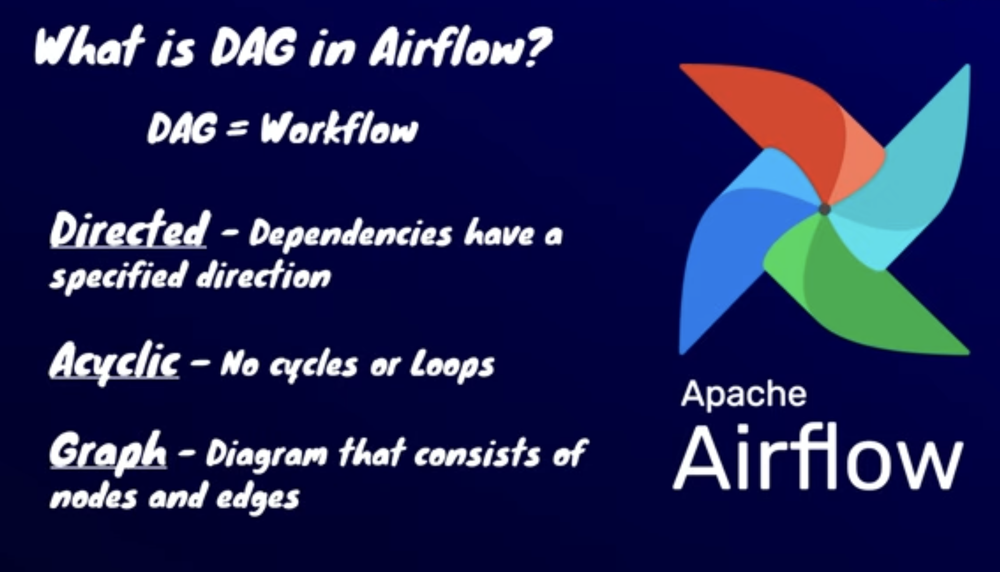

`Acyclic`: means we cant execute one task and later returned back to the same task. 

A single Python file can define multiple DAGs. Airflow doesn’t enforce a one-file-one-DAG rule.

Best practice: Even though multiple DAGs per file is allowed, the usual convention is one DAG per file because:

It’s easier to read, test, and debug.
A parse error in the file breaks every DAG in it.
Git history and ownership are cleaner.
Parse time is per file, so a heavy file slows down all DAGs inside it.

Each task is defined by an operator, operator tells us what needs to be done.

Scheduler: The brain. It parses DAG files, decides which tasks are ready to run (based on schedule, dependencies, and state), and hands them to the executor. It doesn’t run tasks itself.

Executor: The mechanism that determines how and where tasks run. It sits inside the scheduler process and takes queued tasks and sends them to workers. Examples:

LocalExecutor: runs tasks as subprocesses on the same machine
CeleryExecutor: pushes tasks to a queue (Redis/RabbitMQ) for a pool of workers
KubernetesExecutor: spins up a new pod per task

Worker: The process that actually executes the task code and reports the result back to the metadata DB.

Flow: The worker runs the operator → operator uses the hook → hook reads the connection → makes the call to Snowflake/EMR → waits (or uses a sensor) for completion.

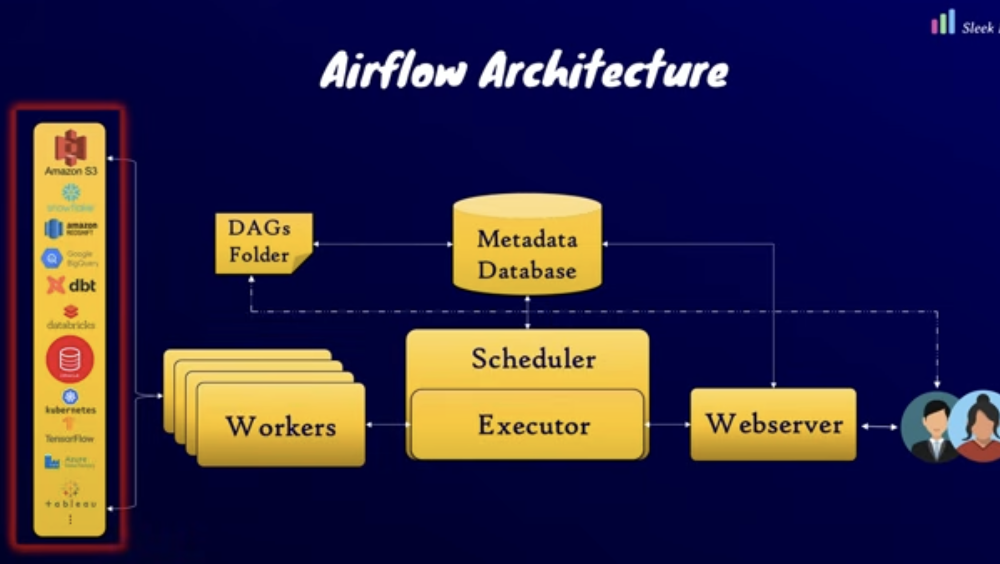

# what are the ways to establish dependencies

a >> b >> c means a, then b, then c (sequential)\
[a, b, c] >> d means a, b, c in parallel, then d

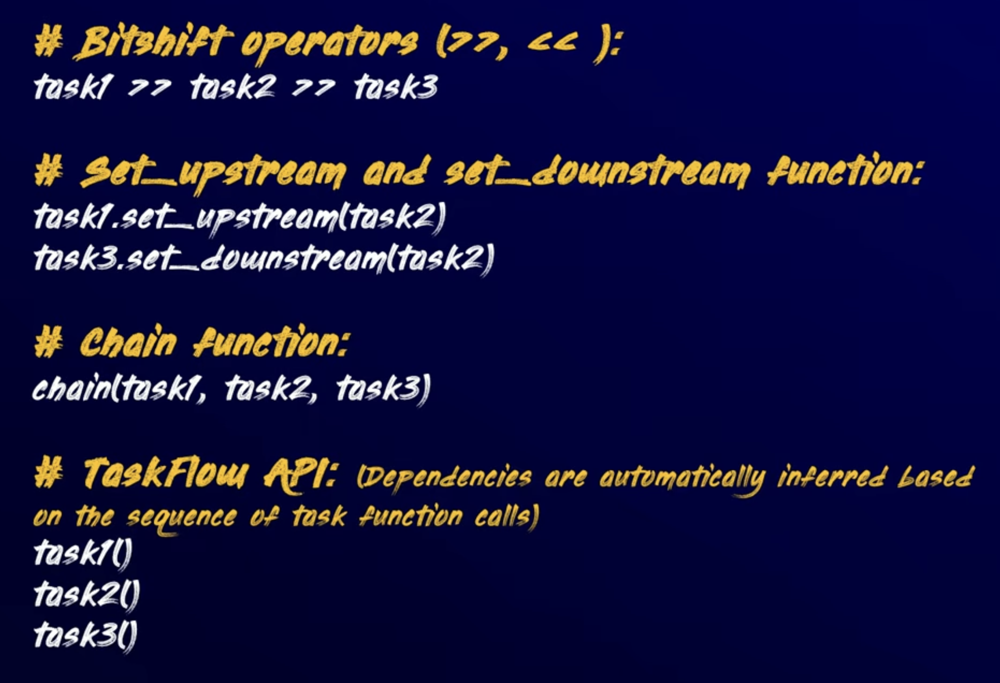

# types of operators

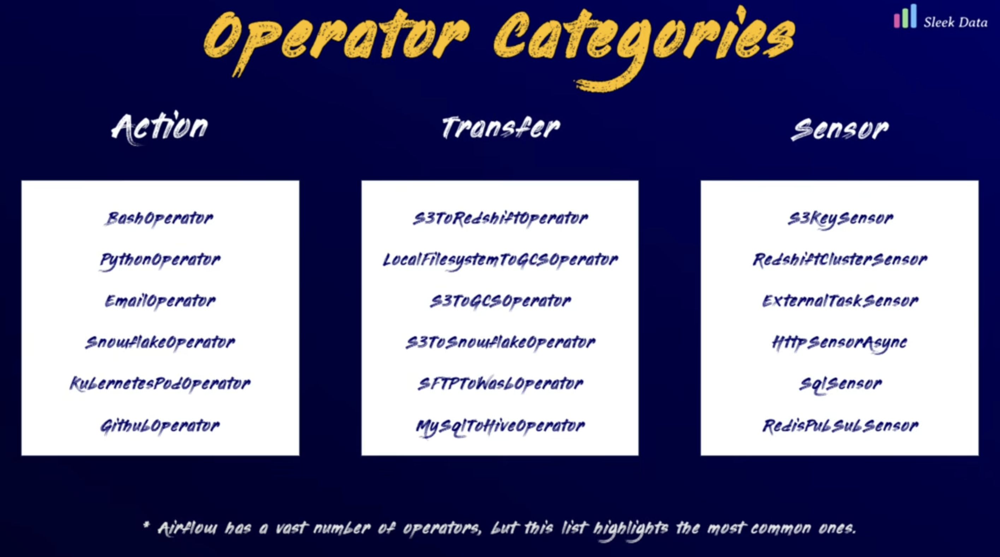

# Variables

Variables are light weight containers to store the key value pairs. Variables created can be used across multiple dags.

##### use `{{var.value.get('support_email)}}`  to get the variable value
#### Two types of variables
1. Regular strings, where the values are any type of string
2. json string, where the value is a json


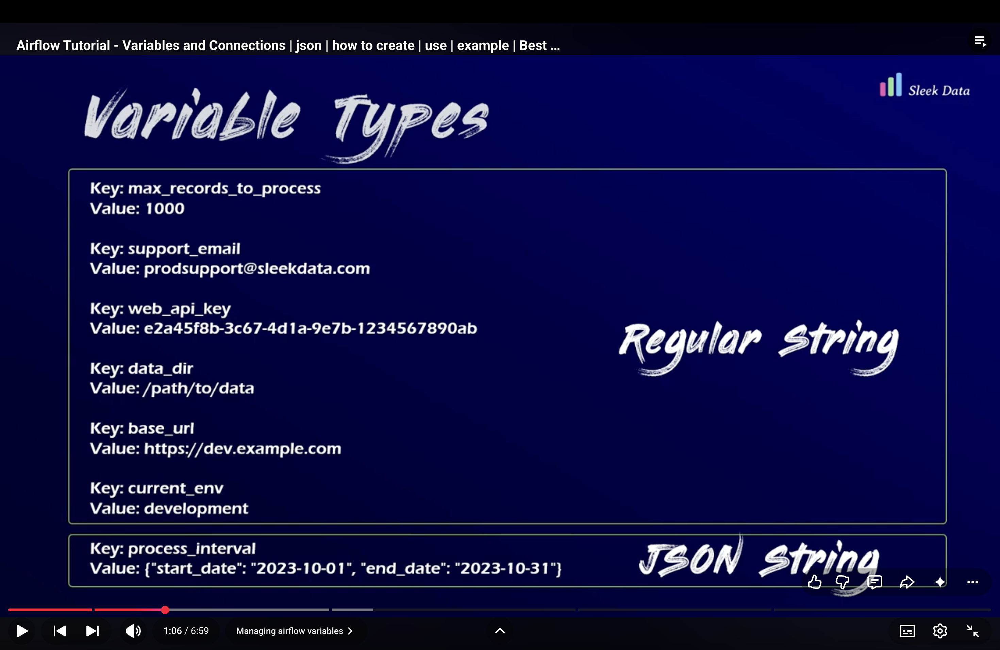

#### Benefits of using varibales

1. changes are easy, just change the one variable
2. env specific
3. security -> masking the variables which have specific keywords(key, secret, access_token, password, private_key)
4. Dynamic dags, json variable bnaya tha na, usi ka use karke dynamic sql

# Connections

Connections are `configurations` objects, they store details required to connect to an external system.\
details required to establish a connection\
\
connection id\
connection name\
host name\
port\
user name\
password\



# Sensors

Sensors are special type of operators which wait for a condition to met, once recieved confirmation, it is marked as true and executes the next downstream task.\
\
Sensors makes the dag more event driven\
\
It continously check, if the given condition met or not,\
it can check if file lands in s3\
data base updated\
or a api is available now?

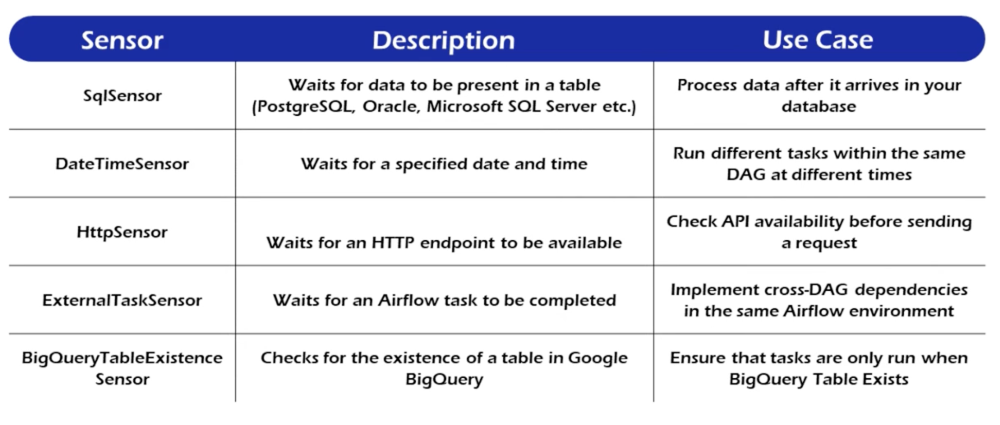

# Deferrables and triggers


Problem:\
A normal sensor or operator (e.g., S3KeySensor, ExternalTaskSensor) occupies a worker slot the whole time it waits, even though it’s just polling or sleeping. If you have 100 sensors waiting on files that arrive in 2 hours, you’ve burned 100 worker slots doing nothing.\
Solution:\
A deferrable operator can suspend itself while waiting, freeing the worker slot, and resume when the external condition is met.
\
\
A separate process, the triggerer, runs the trigger.\
When the trigger fires, the task is rescheduled onto a worker and continues at the method named in method_name.

we can pass the argument in the sensor operator\
check the documentation if the specific operator have the deferrable parameter or not\
\
good way to optimise the worker slot usage and controls the cost.

In [ ]:
wait_for_file = S3KeySensor(
    task_id="wait_for_file",
    bucket_name="my-bucket",
    bucket_key="data/{{ ds }}/file.csv",
    deferrable=True,
)

# Xcoms

Pass data between tasks\
by default, airflow tasks are isolated, tasks cant share data within each other at runtime


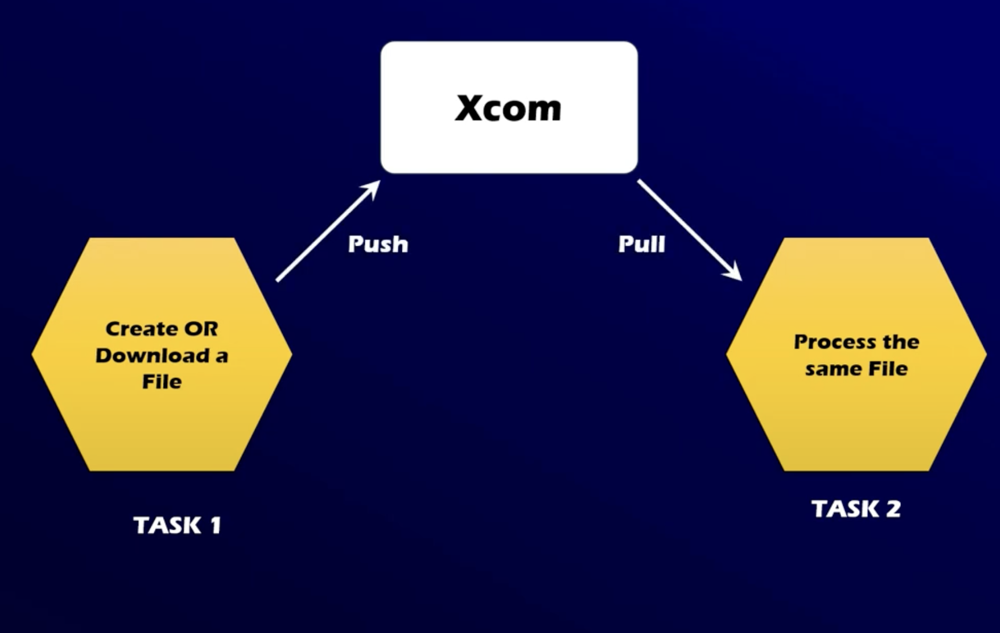

Xcom use karne ke liye ti `TaskInstance` ki jarurat padti hai, we put this in function argument with exact `ti` name and airflow handles the rest work, it will check the function parameters names and if it finds any in Airflow context varibales then it passes that in the func arguments while calling the function. 
\
\
\
And if we want to pass the custom arguments, then pass in a a dag argument.\
\
`op _agrs = ['arg1','arg2','arg3']`

# Hooks

Pre built python classes\
They simplfy out interaction with external systems \
\
ex. s3_hook\
\
It can provide other fucntions to interact with s3 bucket, \
example are:\
check_for_bucket\
get_bucket\
create_bucket\
delete_objects. --> to delete s3 object in a bucket.\
mostly every company provides thre own hooks with in the airflow providers package.\
\
`from airflow.providers.postgres.hooks.postgres import PostgresHook` \
`from airflow.providers.amazon.aws.hooks.s3 import S3Hook`


Data aware scheduling --> means running enabling the execution of dags depending on availability of files\


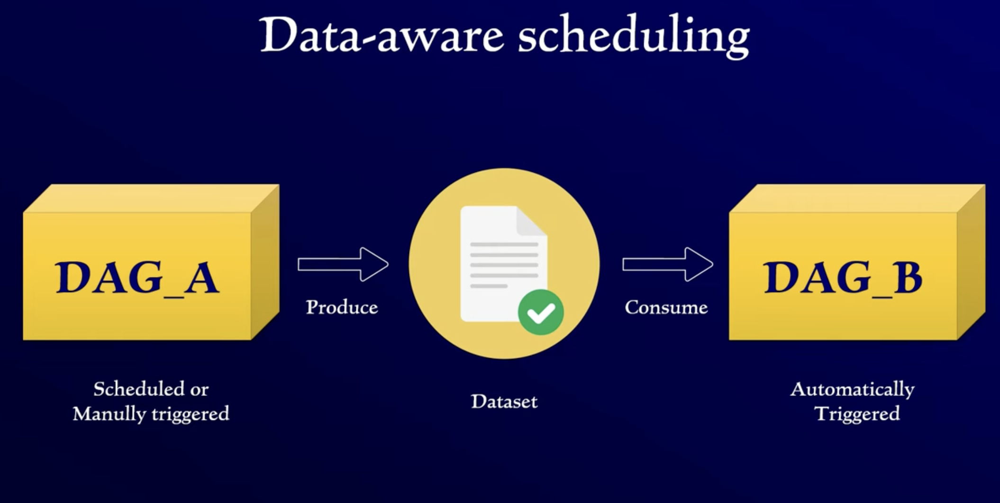

dag_x willl be scheduled to run once all corrosponding dags ran successfully and generated the dataset.

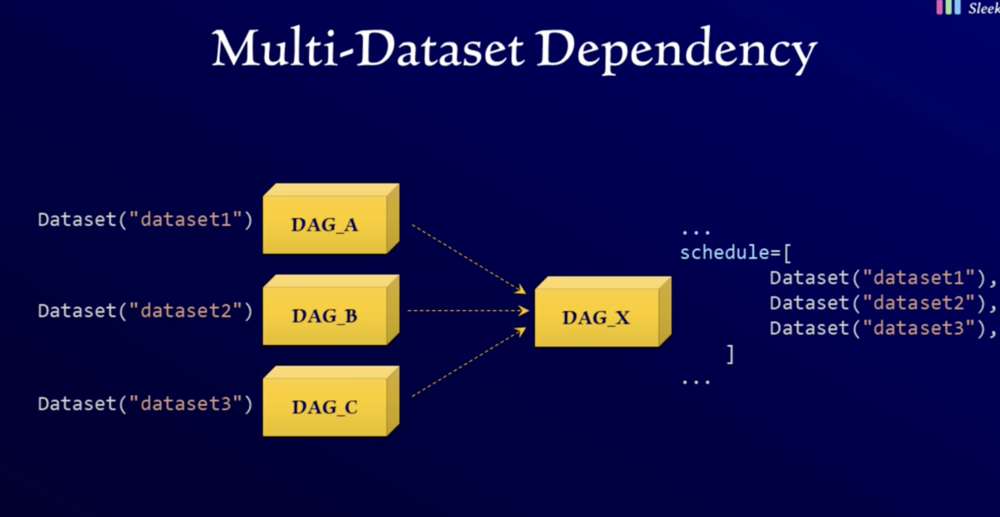

managing task flow, it deifnes how many ways we can set a task to run/not run

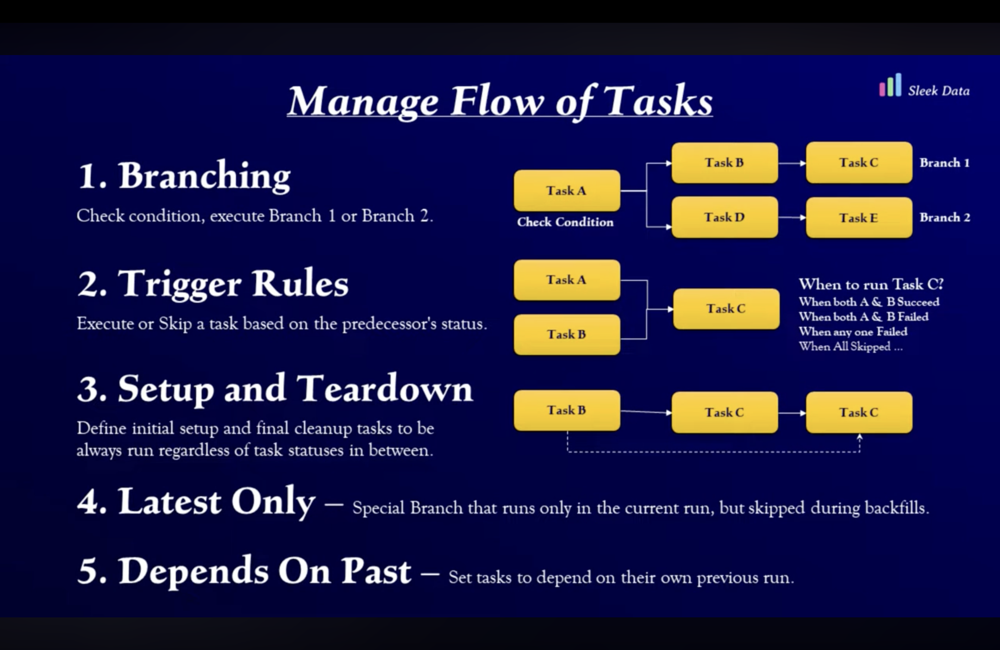

depends on past: if a task needs to run if its previous execution ran successfully, bcz we dont want to run todays execution bcz yesterday run was failed, and root cause has not been yet addressed.\
\
for this , mark the `depends_on_past = True` in the specific task.

Taskflow APIs, we can write `@task` as decorators to define the task item, it will help us to get rid of operators and increase the readibility of code. 